<a href="https://colab.research.google.com/github/lakshanya-j/Projects/blob/main/KMeansClusteringforcollegedata.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

                             Private  Apps  Accept  Enroll  Top10perc  \
Abilene Christian University     Yes  1660    1232     721         23   
Adelphi University               Yes  2186    1924     512         16   
Adrian College                   Yes  1428    1097     336         22   
Agnes Scott College              Yes   417     349     137         60   
Alaska Pacific University        Yes   193     146      55         16   

                              Top25perc  F.Undergrad  P.Undergrad  Outstate  \
Abilene Christian University         52         2885          537      7440   
Adelphi University                   29         2683         1227     12280   
Adrian College                       50         1036           99     11250   
Agnes Scott College                  89          510           63     12960   
Alaska Pacific University            44          249          869      7560   

                              Room.Board  Books  Personal  PhD  Terminal  \
Abilene Ch

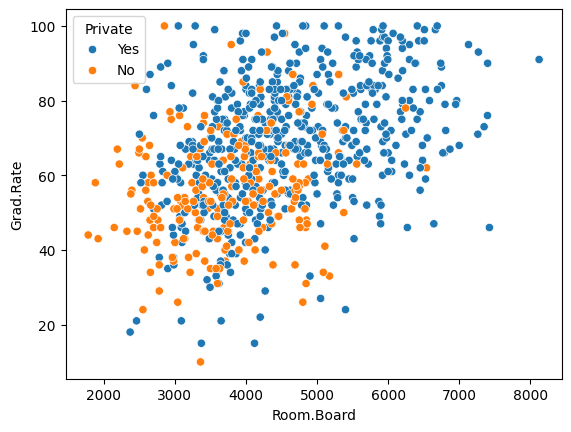

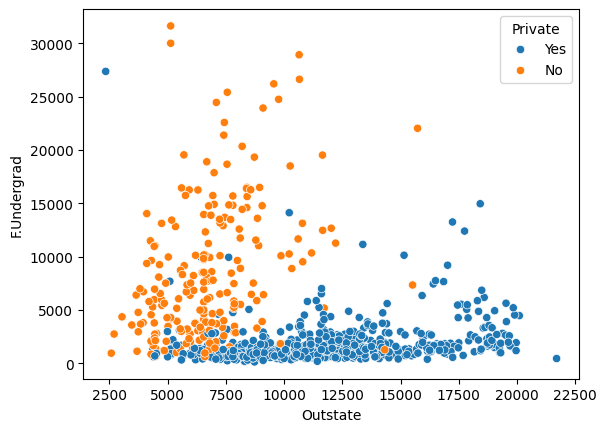

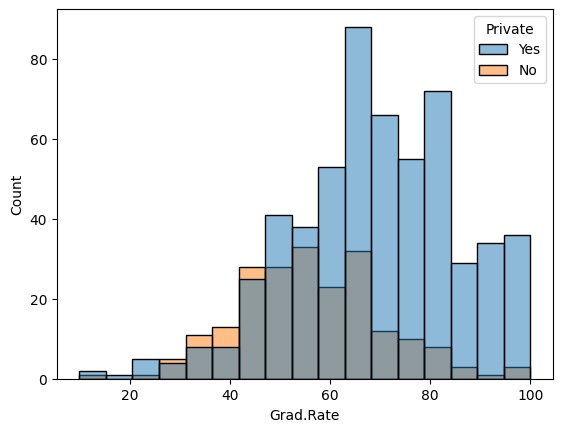

Confusion Matrix:
[[146  66]
 [340 225]]
Classification Report:
              precision    recall  f1-score   support

      Public       0.30      0.69      0.42       212
     Private       0.77      0.40      0.53       565

    accuracy                           0.48       777
   macro avg       0.54      0.54      0.47       777
weighted avg       0.64      0.48      0.50       777



In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, classification_report
df = pd.read_csv("College.csv", index_col=0)

df = df.dropna()
df['Grad.Rate'] = df['Grad.Rate'].clip(upper=100)

print(df.head())
print(df.info())
print(df.isnull().sum())

sns.scatterplot(data=df, x='Room.Board', y='Grad.Rate', hue='Private')
plt.show()

sns.scatterplot(data=df, x='Outstate', y='F.Undergrad', hue='Private')
plt.show()

sns.histplot(data=df, x='Grad.Rate', hue='Private')
plt.show()

y = df['Private'].map({'No': 0, 'Yes': 1})
X = df.drop(columns=['Private'])

X = StandardScaler().fit_transform(X)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X)

private_cluster = df.groupby('Cluster')['Outstate'].mean().idxmax()
y_pred = (df['Cluster'] == private_cluster).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y, y_pred))

print("Classification Report:")
print(classification_report(y, y_pred, target_names=['Public', 'Private']))